# Assignment 2: EDA & Data Description of the Tomato Leaves Dataset

**This notebook**
- Serves as the **data description and EDA** part of the **M2 Draft** for Assignment 2.
- Checks the dataset against the M1 proposal and tests the leakage-prevention requirement.

The Tomato Leaves Dataset combines tomato images from PlantVillage and PlantDoc. Each image has one label: seven diseases or a healthy leaf.

## 0. Setup

Import the tools needed to read image files and explore them.

In [1]:
from pathlib import Path
import hashlib
import re
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image

SEED = 42
NAMES = ['Bacterial spot', 'Early blight', 'Late blight', 'Leaf mold', 'Septoria leaf spot',
         'Tomato yellow leaf curl virus', 'Tomato mosaic virus', 'Healthy']
SPLITS = ['train', 'validation', 'test']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.Series({'Python': sys.version.split()[0], 'NumPy': np.__version__, 'pandas': pd.__version__,
           'Matplotlib': matplotlib.__version__, 'Pillow': PIL.__version__}, name='Version').to_frame()

,Version
Python,3.12.7
NumPy,2.4.5
pandas,3.0.2
Matplotlib,3.10.9
Pillow,10.4.0


**Observation and comment**

The table records the environment used for these outputs. The figures are static, so they stay visible when the notebook is opened without a running kernel.

## 1. Read the dataset

Use the split published in the dataset repository (revision `c029791`). Images are listed by folder; the label is the folder name.

In [2]:
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'Assignment2' else ROOT
sys.path.insert(0, str(ROOT / 'Assignment2'))
from data_loader import list_files, read_tomato, RAW
paths, labels, splits = list_files()
split_counts = pd.DataFrame({SPLITS[s]: np.bincount(labels[splits == s], minlength=8) for s in range(3)},
                            index=pd.Index(NAMES, name='Class'))
split_counts['Total'] = split_counts.sum(axis=1)
split_counts.loc['Total'] = split_counts.sum()
split_counts

,train,validation,test,Total
Class,,,,
Bacterial spot,1930,235,241,2406
Early blight,966,131,117,1214
Late blight,1710,210,209,2129
Leaf mold,999,120,125,1244
Septoria leaf spot,1771,210,223,2204
Tomato yellow leaf curl virus,4930,624,625,6179
Tomato mosaic virus,509,66,59,634
Healthy,1589,200,197,1986
Total,14404,1796,1796,17996


**Observation and comment**

The published split holds 17,996 images: 14,404 for training and 1,796 each for validation and test. These counts match the M1 proposal. Tomato yellow leaf curl virus is the largest class (6,179 images, 4,930 in training) and Tomato mosaic virus the smallest (634 images, 509 in training).

## 2. Class distribution and imbalance

Compare the share of each class in the three partitions. A partition that differs strongly from the training set would make validation or test scores hard to compare.

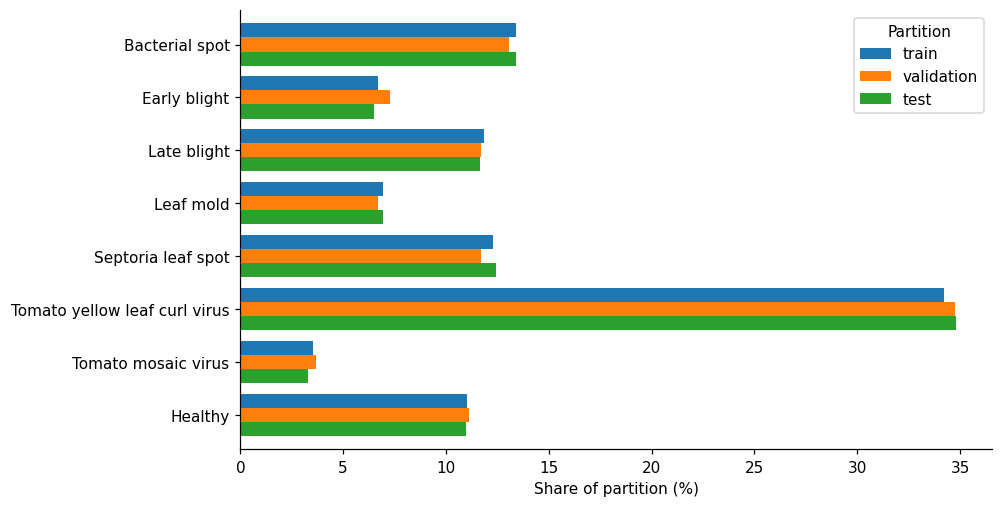

,Value
Largest class,Tomato yellow leaf curl virus
Largest count,6179
Smallest class,Tomato mosaic virus
Smallest count,634
Imbalance ratio,9.7


In [3]:
share = (split_counts.drop(index='Total')[SPLITS] / split_counts.loc['Total', SPLITS]) * 100
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
share.plot.barh(ax=ax, width=0.8)
ax.invert_yaxis()
ax.set(xlabel='Share of partition (%)', ylabel='')
ax.legend(title='Partition')
plt.show()
counts = split_counts.drop(index='Total')['Total']
pd.Series({'Largest class': NAMES[counts.argmax()], 'Largest count': counts.max(),
           'Smallest class': NAMES[counts.argmin()], 'Smallest count': counts.min(),
           'Imbalance ratio': round(counts.max() / counts.min(), 1)}, name='Value').to_frame()

**Observation and comment**

The largest class is 9.7 times the size of the smallest. The three partitions have almost the same class shares, so validation and test scores describe the same label mix as training. Accuracy alone would be dominated by the large virus class, so the experiments report macro-F1 as well and use it to select checkpoints.

## 3. Original image size and file format

Read only the image headers to learn the original resolution before the resize to 224 × 224.

In [4]:
def header(path):
    with Image.open(RAW / path) as image:
        return image.size[0], image.size[1], image.format, image.mode
sizes = pd.DataFrame([header(p) for p in paths], columns=['width', 'height', 'format', 'mode'])
sizes['class'] = [NAMES[l] for l in labels]
sizes['split'] = [SPLITS[s] for s in splits]
sizes['pixels'] = sizes['width'] * sizes['height']
summary = pd.concat({'width': sizes['width'].describe(), 'height': sizes['height'].describe()}, axis=1).round(1)
display(summary)
display(sizes.groupby(['width', 'height']).size().sort_values(ascending=False).head(6).rename('images').to_frame())
display(sizes[['format', 'mode']].value_counts().rename('images').to_frame())

,width,height
count,17996.0,17996.0
mean,285.9,279.8
std,223.6,186.9
min,115.0,85.0
25%,256.0,256.0
50%,256.0,256.0
75%,256.0,256.0
max,6000.0,6000.0


,,images
width,height,
256,256,16889
224,224,317
800,600,23
1600,1200,19
1024,768,15
1200,1600,13


,,images
format,mode,
JPEG,RGB,17995
PNG,RGBA,1


**Observation and comment**

17,995 files are RGB JPEG and one is an RGBA PNG, which the loader converts to RGB. 16,889 images (93.9%) are 256 × 256; 317 are 224 × 224, and the rest range from 115 × 85 to 6000 × 6000. Resizing every image to 224 × 224 therefore leaves most of the data almost unchanged, but it stretches the minority of non-square images.

## 4. Image sources

File names are anonymised (`image (N).JPG`), so the source cannot be read from the name. PlantVillage photographs are 256 × 256 crops, while PlantDoc images are web photographs of mixed size. Use the image size as a rough source label.

In [5]:
sizes['source'] = np.where((sizes['width'] == 256) & (sizes['height'] == 256), '256 x 256 (PlantVillage-style)', 'Other size (PlantDoc / web-style)')
table = pd.crosstab(sizes['class'], sizes['source']).reindex(NAMES)
table['Other share (%)'] = (table.iloc[:, 1] / table.sum(axis=1) * 100).round(1)
display(table)
display(pd.crosstab(sizes['split'], sizes['source']).reindex(SPLITS))

source,256 x 256 (PlantVillage-style),Other size (PlantDoc / web-style),Other share (%)
class,,,
Bacterial spot,2274,132,5.5
Early blight,1108,106,8.7
Late blight,2004,125,5.9
Leaf mold,1110,134,10.8
Septoria leaf spot,1995,209,9.5
Tomato yellow leaf curl virus,5990,189,3.1
Tomato mosaic virus,539,95,15.0
Healthy,1869,117,5.9


source,256 x 256 (PlantVillage-style),Other size (PlantDoc / web-style)
split,,
train,13457,947
validation,1718,78
test,1714,82


**Observation and comment**

File names are anonymised, so the size rule is only a rough proxy for the source. Under that rule, 6.6% of training images (947) have a size other than 256 × 256, against 4.3% of validation and 4.6% of test images. The share of such images varies by class, from 3.1% for Tomato yellow leaf curl virus to 15.0% for Tomato mosaic virus. A class may therefore partly be recognised by image style rather than by disease, and Tomato mosaic virus, the smallest class, has the largest share of web-style photographs.

## 5. Representative images

Show one random training image per class at the 224 × 224 model input size.

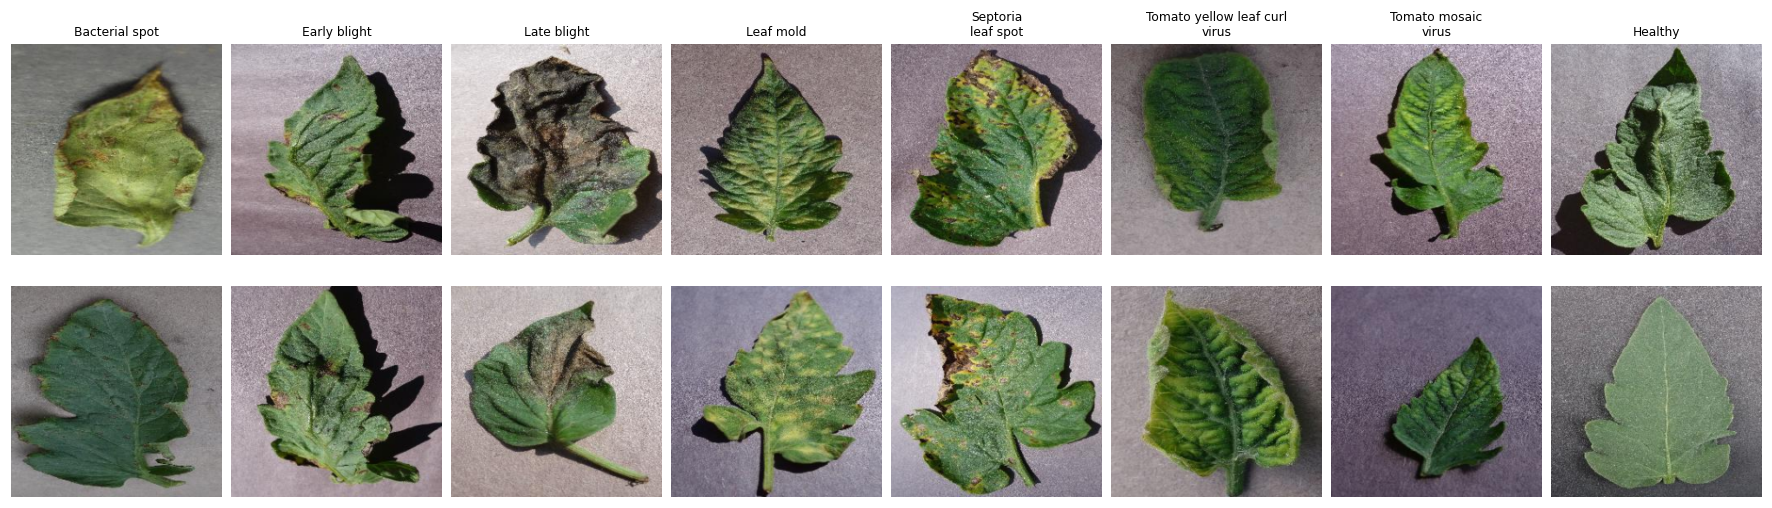

In [6]:
images, cached_labels, cached_splits, cached_paths = read_tomato()
assert (cached_labels == labels).all() and (cached_splits == splits).all()
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6), layout='constrained')
for label in range(8):
    pool = np.flatnonzero((labels == label) & (splits == 0))
    for row, index in enumerate(rng.choice(pool, 2, replace=False)):
        axes[row, label].imshow(images[index])
        axes[row, label].axis('off')
    axes[0, label].set_title(NAMES[label].replace(' virus', '\nvirus').replace('Septoria ', 'Septoria\n'), fontsize=8)
plt.show()

**Observation and comment**

Most sampled images show a single leaf on a plain grey background. The disease cues are small: spots, yellow areas, curled edges or dark patches. Several classes look alike at this size, for example Early blight, Septoria leaf spot and Bacterial spot, so fine texture will matter for the models.

## 6. Colour and brightness

Summarise the mean RGB value of every training image by class. Disease classes may differ in colour, which a small CNN can exploit.

,R,G,B,Brightness
class,,,,
Bacterial spot,102.4,109.7,93.3,101.8
Early blight,109.3,114.0,100.4,107.9
Late blight,113.2,115.4,101.8,110.1
Leaf mold,111.4,117.8,111.7,113.7
Septoria leaf spot,129.5,132.4,117.0,126.3
Tomato yellow leaf curl virus,111.8,119.7,89.9,107.2
Tomato mosaic virus,116.9,118.1,114.0,116.3
Healthy,114.3,119.6,109.8,114.6


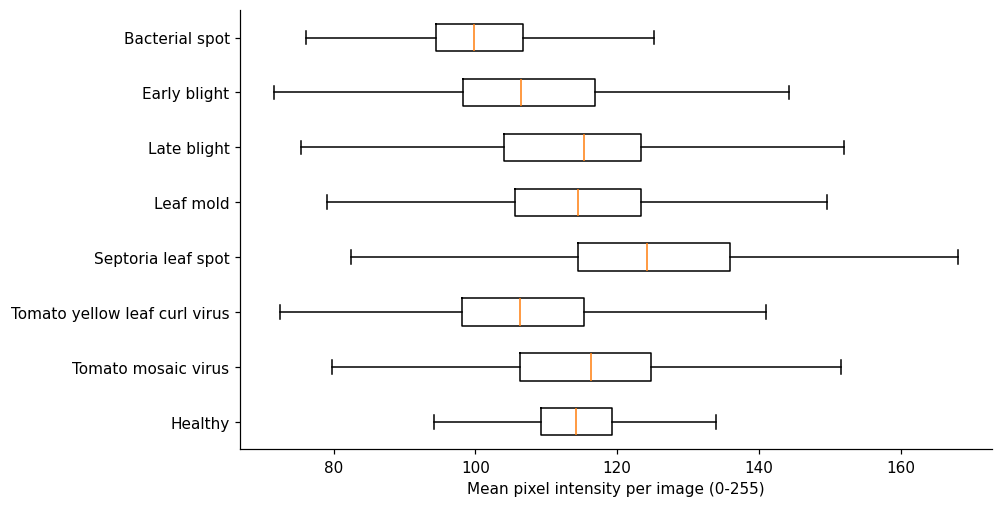

,Training mean (0-1)
R,0.4438
G,0.4660
B,0.3936


In [7]:
train_mask = splits == 0
mean_rgb = images[train_mask].reshape(train_mask.sum(), -1, 3).mean(axis=1)
train_labels = labels[train_mask]
colour = pd.DataFrame(mean_rgb, columns=['R', 'G', 'B'])
colour['Brightness'] = mean_rgb.mean(axis=1)
colour['class'] = [NAMES[l] for l in train_labels]
display(colour.groupby('class').mean().reindex(NAMES).round(1))
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
ax.boxplot([colour.loc[colour['class'] == n, 'Brightness'] for n in NAMES], vert=False, tick_labels=NAMES, showfliers=False)
ax.invert_yaxis()
ax.set(xlabel='Mean pixel intensity per image (0-255)')
plt.show()
pd.Series({'R': images[train_mask].reshape(-1, 3)[::50, 0].mean() / 255, 'G': images[train_mask].reshape(-1, 3)[::50, 1].mean() / 255,
           'B': images[train_mask].reshape(-1, 3)[::50, 2].mean() / 255}, name='Training mean (0-1)').round(4).to_frame()

**Observation and comment**

Mean colour differs by class. Septoria leaf spot images are the brightest (126.3) and Bacterial spot the darkest (101.8). Tomato yellow leaf curl virus has the lowest blue value (89.9), against 111.7 for Leaf mold and 114.0 for Tomato mosaic virus. Colour therefore carries some class information that a small CNN can use, but it may also reflect lighting or background differences between sources. The training mean (0.444, 0.466, 0.394) is close to the ImageNet mean used for normalisation.

## 7. Duplicates and leakage between partitions

The M1 proposal requires that an original photograph and its copies stay in one partition. Test this on the published split in two ways: byte-identical files, and visually near-identical images found with a 64-bit difference hash (Hamming distance of at most 4).

In [8]:
md5 = np.array([hashlib.md5((RAW / p).read_bytes()).hexdigest() for p in paths])
exact = pd.DataFrame({'md5': md5, 'split': [SPLITS[s] for s in splits]})
groups = exact.groupby('md5')['split'].agg(['count', lambda s: len(set(s))])
groups.columns = ['copies', 'partitions']
pd.Series({'Distinct files': int((groups['copies'] == 1).sum()),
           'Files with an exact copy': int((groups['copies'] > 1).sum()),
           'Copies spanning two or more partitions': int((groups['partitions'] > 1).sum())}, name='Count').to_frame()

,Count
Distinct files,17938
Files with an exact copy,29
Copies spanning two or more partitions,3


**Observation and comment**

58 images form 29 pairs of byte-identical files. In 3 of those pairs the two copies sit in different partitions. Exact copies are rare, so they are not the main leakage risk.

In [9]:
def dhash(image):
    small = np.asarray(Image.fromarray(image).convert('L').resize((9, 8), Image.BILINEAR), dtype=np.int16)
    bits = (small[:, 1:] > small[:, :-1]).reshape(-1)
    return np.packbits(bits)
hashes = np.stack([dhash(image) for image in images])
popcount = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
def nearest(query, reference, skip_self=False):
    best = np.full(len(query), 65, dtype=np.int32)
    where = np.zeros(len(query), dtype=np.int64)
    for start in range(0, len(query), 500):
        chunk = query[start:start + 500]
        distance = popcount[np.bitwise_xor(chunk[:, None, :], reference[None, :, :])].sum(axis=2)
        if skip_self:
            distance[np.arange(len(chunk)), start + np.arange(len(chunk))] = 65
        best[start:start + len(chunk)] = distance.min(axis=1)
        where[start:start + len(chunk)] = distance.argmin(axis=1)
    return best, where
train_hash = hashes[splits == 0]
rows, near = [], {}
for s in (1, 2):
    distance, where = nearest(hashes[splits == s], train_hash)
    near[s] = (distance, where)
    rows.append({'Partition': SPLITS[s], 'Images': len(distance),
                 'Identical hash (d=0)': int((distance == 0).sum()),
                 'Near duplicate (d<=4)': int((distance <= 4).sum()),
                 'Share (%)': round((distance <= 4).mean() * 100, 1)})
distance, _ = nearest(train_hash, train_hash, skip_self=True)
rows.append({'Partition': 'train (within itself)', 'Images': len(distance), 'Identical hash (d=0)': int((distance == 0).sum()),
             'Near duplicate (d<=4)': int((distance <= 4).sum()), 'Share (%)': round((distance <= 4).mean() * 100, 1)})
pd.DataFrame(rows).set_index('Partition')

,Images,Identical hash (d=0),Near duplicate (d<=4),Share (%)
Partition,,,,
validation,1796,5,88,4.9
test,1796,3,88,4.9
train (within itself),14404,719,2873,19.9


**Observation and comment**

Near duplicates are much more common than exact copies. 88 validation images (4.9%) and 88 test images (4.9%) have a training image within Hamming distance 4. Inside the training set, 2,873 images (19.9%) have another training image that close. The published split therefore does not fully keep each photograph and its copies in one partition, which the M1 proposal assumed.

,Near duplicates,Same label as train match
Partition,,
validation,88,55
test,88,63


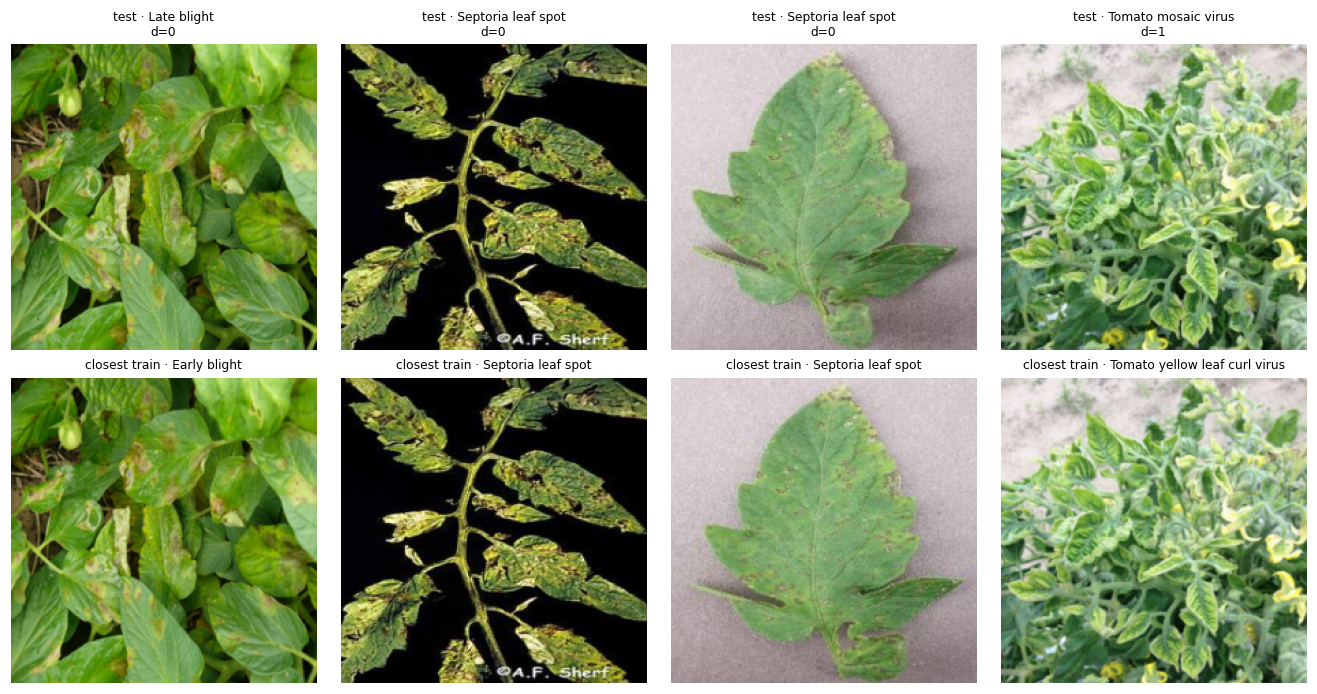

In [10]:
# do the near duplicates agree on the label?
train_index = np.flatnonzero(splits == 0)
rows = []
for s in (1, 2):
    distance, where = near[s]
    idx = np.flatnonzero(splits == s)
    hit = distance <= 4
    same = labels[idx[hit]] == labels[train_index[where[hit]]]
    rows.append({'Partition': SPLITS[s], 'Near duplicates': int(hit.sum()), 'Same label as train match': int(same.sum())})
display(pd.DataFrame(rows).set_index('Partition'))
distance, where = near[2]
idx = np.flatnonzero(splits == 2)
pick = np.argsort(distance)[:4]
fig, axes = plt.subplots(2, 4, figsize=(12, 6.2), layout='constrained')
for column, p in enumerate(pick):
    axes[0, column].imshow(images[idx[p]]); axes[0, column].set_title(f'test · {NAMES[labels[idx[p]]]}\nd={distance[p]}', fontsize=8)
    axes[1, column].imshow(images[train_index[where[p]]]); axes[1, column].set_title(f'closest train · {NAMES[labels[train_index[where[p]]]]}', fontsize=8)
    axes[0, column].axis('off'); axes[1, column].axis('off')
plt.show()

**Observation and comment**

Only 55 of the 88 validation matches and 63 of the 88 test matches carry the same label as the training image. The four closest test pairs are clearly the same photograph (distance 0 or 1), and in two of them the label differs: one image is Late blight in test and Early blight in training, another is Tomato mosaic virus in test and Tomato yellow leaf curl virus in training. This is evidence of duplicated photographs and some conflicting labels. Only the closest pairs have been checked by eye; with a threshold of 4 some of the 176 matches may be merely similar images, so the counts are an upper bound on true duplicates.

## 8. Inspect preprocessing

Show one training image before preprocessing, after the 224 × 224 resize, and after the two random flips used for training augmentation. Normalisation uses the ImageNet mean and standard deviation, which the pretrained ResNet-18 expects.

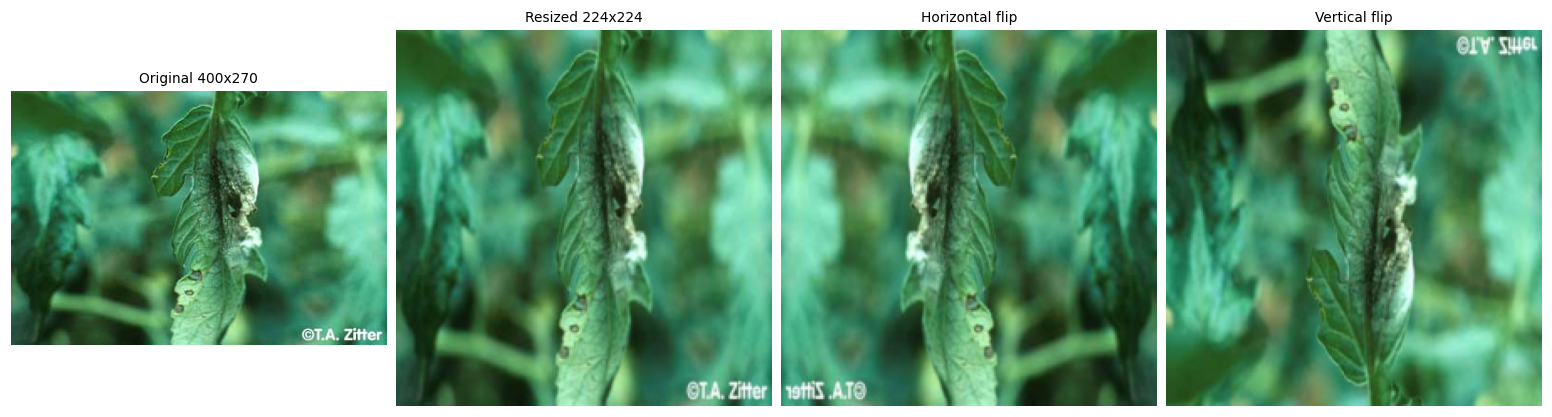

,Mean,Std
Channel,,
R,-0.900,0.620
G,0.330,0.850
B,-0.191,0.796


In [11]:
import torch
original = Image.open(RAW / paths[np.flatnonzero((labels == 2) & (splits == 0))[0]]).convert('RGB')
resized = images[np.flatnonzero((labels == 2) & (splits == 0))[0]]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), layout='constrained')
for ax, (title, image) in zip(axes, [(f'Original {original.size[0]}x{original.size[1]}', np.asarray(original)), ('Resized 224x224', resized),
                                      ('Horizontal flip', resized[:, ::-1]), ('Vertical flip', resized[::-1])]):
    ax.imshow(image); ax.set_title(title, fontsize=9); ax.axis('off')
plt.show()
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1); std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
normalised = (torch.from_numpy(resized).permute(2, 0, 1).float() / 255 - mean) / std
pd.DataFrame({'Channel': ['R', 'G', 'B'], 'Mean': normalised.mean((1, 2)).numpy().round(3), 'Std': normalised.std((1, 2)).numpy().round(3)}).set_index('Channel')

**Observation and comment**

The resized image keeps the leaf visible, and flips produce plausible views because a leaf has no fixed orientation. After normalisation the channels of this single image do not have zero mean and unit variance, because the statistics come from ImageNet, not from this image.

## 9. EDA conclusions

Collect what the checks above mean for the baseline and pretrained models.

- **Split and size.** The data match the M1 proposal: 17,996 images in 8 classes and a 14,404 / 1,796 / 1,796 split.
- **Imbalance.** The class ratio is 9.7 to 1, so accuracy and macro-F1 can differ. Checkpoints are selected on validation macro-F1, and per-class results are examined in the results notebook.
- **Leakage.** Exact copies are rare, but about 5% of validation and test images have a near-duplicate in the training set, and some of those carry a different label. The M1 leakage-prevention rule is not met by the published split. For this draft the published split is kept so that results stay comparable with the proposal; the effect on the test score is measured separately in the results notebook, and a group-aware re-split is a candidate for the final milestone.
- **Source style.** About 6% of images look like web photographs rather than lab crops, and the share differs by class. This is a possible shortcut for the models and a reason to look at errors by source.
- **Preprocessing.** Resize to 224 × 224, ImageNet normalisation, and random horizontal and vertical flips for training only. The same input pipeline serves the small CNN and ResNet-18.